# Лабораторная работа № 7
## Устойчивый и легальный пайплайн

Вшивков К. И., ПМИ-3-2025. Вариант 6.

Цель: доработать сборщик для трёх доменов, ограничить нагрузку, обработать ошибки и сравнить обычный и оптимизированный сбор.

Используем парсинг прежних работ: Books to Scrape, ScrapingCourse и World Bank. Внешний контроль от 26.10.2026 содержит 35 записей. Опыты A/B/C выполняются на локальном HTTP-стенде с копиями данных: 12 страниц, 60 записей. В поле host журнала стенда указан моделируемый домен, фактическое соединение идёт на 127.0.0.1.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

BASE = Path.cwd()
if not (BASE / "reports/run_report_A.json").exists():
    raise RuntimeError("Откройте ноутбук с рабочей папкой лабораторной № 7")

def read(name):
    return json.loads((BASE / name).read_text(encoding="utf-8"))

comparison = [read(f"reports/run_report_{p}.json") for p in ["A", "B", "C"]]
metrics = ["requests", "codes", "error_fraction", "rate_429_403", "retries",
           "median_ms", "p95_ms", "traffic_bytes", "responses_304", "breaker_activations",
           "records", "rejected", "duration_seconds", "status"]
display(pd.DataFrame(comparison).set_index("run_id")[metrics].T)
print("Внешний контроль от 26.10.2026:")
display(pd.Series(read("reports/live.json")).drop(["alerts", "codes"]).to_frame("Значение"))


run_id,A,B,C
requests,18,19,12
codes,"{'200': 17, '429': 1}","{'200': 18, '429': 1}","{'200': 9, '304': 3}"
error_fraction,0.055556,0.052632,0.0
rate_429_403,0.055556,0.052632,0.0
retries,0,1,0
median_ms,2.5195,16.709,7.8575
p95_ms,3.75935,22.2394,19.09665
traffic_bytes,13088,14094,1656
responses_304,0,0,3
breaker_activations,0,0,0


Внешний контроль от 26.10.2026:


,Значение
run_id,live
requests,7
error_fraction,0.0
rate_429_403,0.0
retries,0
median_ms,579.052
p95_ms,984.6841
traffic_bytes,66998
responses_304,1
breaker_activations,0


# Часть 1. Python: аудит, robots.txt и скорость
В прежних работах были таймауты, паузы, повторы и Scrapy AutoThrottle. Добавлены общий HTTP-клиент, token bucket по доменам, full jitter, бюджет времени, предохранитель, ETag, watermark, детектор и JSONL-журнал.

Лимиты: Books 2 запроса/с, ScrapingCourse 1 запрос/с, World Bank 1,5 запроса/с; burst=1, jitter=25%. При медленном ответе задержка увеличивается; 429/503 дополнительно удваивают её. Crawl-delay имеет приоритет. Отсутствие robots.txt с кодом 404 означает отсутствие опубликованных правил, а не разрешение на неограниченную нагрузку. При ошибке загрузки robots сбор домена прекращается.

На домен выделен один поток. Файловая блокировка DomainLease не позволяет другому процессу одновременно взять тот же домен в общей рабочей папке. Для четырёх процессов на одной машине сохраняется один владелец домена; на разных машинах потребуется общая очередь или Redis.

Для малого внешнего контроля нужны 3, 2 и 2 запроса по доменам с учётом robots и условного GET. Базовые интервалы 0,5 / 1 / 0,67 с дают плановый бюджет интервалов 1,5 / 2 / 1,34 с. Измеренная латентность обычной страницы: 0,473 / 0,627 / 0,074 с. Интервалы больше этих значений, запросы одного домена не перекрываются. При увеличении латентности адаптивная задержка увеличивается. Это локально выбранные ограничения учебного сбора, а не заявленные квоты сайтов.


In [2]:
display(pd.DataFrame(read('reports/live_robots.json')))
print('Проверки реальных ответов:')
display(pd.DataFrame(read('reports/live_detection.json')))
if (BASE/'reports/rate_validation.json').exists():display(pd.DataFrame(read('reports/rate_validation.json')))

,host,status,state,crawl_delay,request_rate,sitemaps,configured_rps,effective_rps,probe_url,can_fetch
0,books.toscrape.com,404,missing_404,0,None,[],2.0,2.0,https://books.toscrape.com/catalogue/page-1.html,True
1,www.scrapingcourse.com,200,present,0,None,[],1.0,1.0,https://www.scrapingcourse.com/button-click,True
2,api.worldbank.org,404,missing_404,0,None,[],1.5,1.5,https://api.worldbank.org/v2/country/RUS/indic...,True


Проверки реальных ответов:


,host,status,verdict,reason,bytes,conditional_status
0,books.toscrape.com,200.0,ok,,50469.0,NaN
1,books.toscrape.com,NaN,NaN,NaN,NaN,304.0
2,www.scrapingcourse.com,200.0,ok,,15572.0,NaN
3,api.worldbank.org,200.0,ok,,714.0,NaN


,host,limit_rps,requests,min_interval_seconds,required_min_seconds,passed
0,books.toscrape.com,2.0,7,0.5005,0.5000,True
1,www.scrapingcourse.com,1.0,6,1.0005,1.0000,True
2,api.worldbank.org,1.5,6,0.6673,0.6667,True


### 2. Повторы и предохранитель
Сетевой сбой, 429 и 5xx допускают повтор; 4xx, кроме 429, не повторяются. Для 401 фиксируется необходимость обновления токена, для 403 — инцидент и остановка домена. Максимум 3 попытки, бюджет URL 20 с. Backoff: random(0, min(3, 0.3×2^(attempt−1))). Retry-After имеет приоритет, поддерживаются секунды и HTTP-дата. Если задержка не помещается в бюджет, запрос не отправляется.

Предохранитель открывается после трёх последовательных временных отказов. Пока домен остановлен, другие продолжают работу. Через 1,5 с допускается одна проба; успех закрывает предохранитель.

In [3]:
display(pd.DataFrame(read('reports/retry_scenarios.json')))
isolation=pd.read_json(BASE/'logs/run_isolation.jsonl',lines=True)
display(isolation[isolation.event.isin(['request','breaker_open','breaker_skip','breaker_half_open','breaker_closed'])][['ts','event','host','status','attempt']])
assert read('reports/isolation.json')['breaker_activations']==1

,scenario,attempts,statuses,delay_sources,final_status
0,/fault/429-number,2,"[429, 200]","[Retry-After, none]",200
1,/fault/429-date,2,"[429, 200]","[Retry-After, none]",200
2,/fault/429-plain,2,"[429, 200]","[backoff, none]",200
3,/status/404,1,[404],[none],404
4,/status/401,1,[401],[none],401


,ts,event,host,status,attempt
0,2026-11-07T10:53:31.815460+00:00,request,books.toscrape.com,200.0,1
1,2026-11-07T10:53:32.424621+00:00,request,books.toscrape.com,503.0,1
2,2026-11-07T10:53:32.961593+00:00,request,books.toscrape.com,503.0,2
3,2026-11-07T10:53:33.995826+00:00,request,books.toscrape.com,503.0,3
4,2026-11-07T10:53:33.996325+00:00,breaker_open,books.toscrape.com,NaN,0
5,2026-11-07T10:53:33.996774+00:00,breaker_skip,books.toscrape.com,NaN,0
6,2026-11-07T10:53:34.198513+00:00,request,www.scrapingcourse.com,200.0,1
7,2026-11-07T10:53:35.404008+00:00,request,www.scrapingcourse.com,200.0,1
8,2026-11-07T10:53:35.551997+00:00,request,api.worldbank.org,200.0,1
9,2026-11-07T10:53:36.360827+00:00,request,api.worldbank.org,200.0,1


### 3. Снижение нагрузки
ETag и Last-Modified сохраняются между прогонами вместе с телом ответа. Ответ 304 использует кэш. gzip измеряется по реально переданным сжатым байтам до распаковки. Watermark сравнивается с lastmod локального manifest; неизменившиеся страницы берутся из кэша без HTTP-запроса.

Сравнение выполняется на одинаковых 12 страницах и 60 ожидаемых записях. A теряет одну страницу при 429. B восстанавливает её повтором. C использует сохранённое состояние B и получает все записи, включая неизменившиеся из кэша. Число запросов в таблице включает robots и manifest. Отдельная таблица механизмов сравнивает только обращения за данными.

In [4]:
display(pd.DataFrame(read('reports/mechanisms.json')))
a,b,c=comparison
print('Цена вежливости B-A, с:',round(b['duration_seconds']-a['duration_seconds'],3))
print('Экономия трафика C относительно B, %:',round(100*(1-c['traffic_bytes']/b['traffic_bytes']),2))
assert c['responses_304']>=3 and c['skipped_incremental']==6
print('304 получен также на настоящем Books to Scrape:',read('reports/live.json')['responses_304'])

,mechanism,requests_before,requests_after,bytes_before,bytes_after,traffic_saved_percent,measurement
0,Условный GET,1,1,991,0,100.00,NaN
1,gzip,1,1,991,319,67.81,NaN
2,Watermark: неизменившиеся страницы пропускаются,12,6,12810,6448,49.66,Размеры реальных ответов стенда; отбор по last...


Цена вежливости B-A, с: 5.764
Экономия трафика C относительно B, %: 88.25
304 получен также на настоящем Books to Scrape: 1


### 4. Детектор и наблюдаемость
Детектор проверяет код, маркеры captcha/access denied, размер тела и ожидаемое содержимое. Блокировка сохраняет тело и заголовки, прекращает запросы домена и даёт код возврата 2. Отдельно проверены заглушка HTTP 200 и HTTP 403. История измеренных B/C используется для теста падения объёма на 20% и среднего размера ответа на 30%.

Пороги: ошибки >10%, 429/403 >5%, p95 >3 с, хотя бы одно открытие предохранителя, отбраковка >5%, пустой результат. В маленьких A/B даже один 429 превышает 5%, поэтому статус красный несмотря на успешный повтор в B. Это сигнал наблюдения; принудительная остановка предусмотрена при блокировке домена. C проходит без оповещений.

Число запросов включает неудачные попытки; повторы не скрываются из доли ошибок. Полный набор метрик выведен в первой таблице.


block_captcha ['books.toscrape.com'] red
block_403 ['books.toscrape.com'] red


,metric,median,value,deviation,status
0,records,60.000000,20,0.666667,red
1,mean_body_bytes,1038.541667,20,0.980742,red


A [{'metric': 'rate_429_403', 'value': 0.05555555555555555, 'threshold': 0.05, 'reason': '429/403 более 5%'}]
B [{'metric': 'rate_429_403', 'value': 0.05263157894736842, 'threshold': 0.05, 'reason': '429/403 более 5%'}]
C []


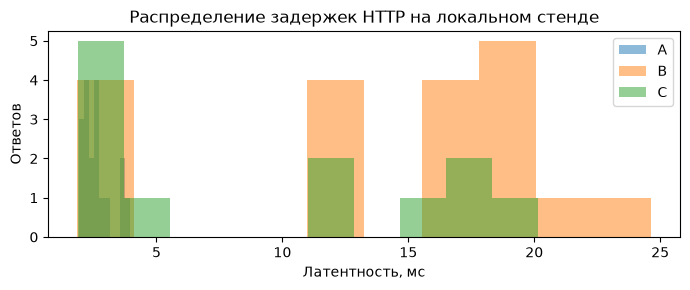

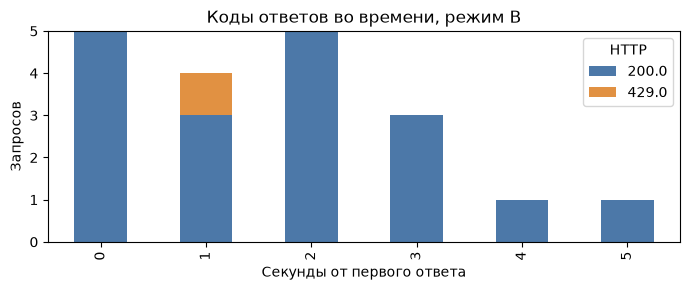

In [5]:
for name in ['block_captcha','block_403']:
    r=read(f'reports/{name}.json')
    print(name,r['blocked_domains'],r['status'])
display(pd.DataFrame(read('reports/degradation_demo.json')['findings']))
for report in comparison:
    print(report['run_id'],report['alerts'])
logs=[]
for profile in ['A','B','C']:
    logs.append(pd.read_json(BASE/f'logs/run_{profile}.jsonl',lines=True))
events=pd.concat(logs,ignore_index=True)
requests=events[events.event=='request'].copy()
plt.rcParams['font.family']='DejaVu Sans'
fig,ax=plt.subplots(figsize=(7,3))
for profile in ['A','B','C']:
    ax.hist(requests.loc[requests.run_id==profile,'ms'],bins=10,alpha=.5,label=profile)
ax.set(title='Распределение задержек HTTP на локальном стенде',xlabel='Латентность, мс',ylabel='Ответов');ax.legend()
fig.tight_layout();fig.savefig(BASE/'reports/latency.png',dpi=160);plt.show()
breq=requests[requests.run_id=='B'].copy()
breq['second']=(pd.to_datetime(breq.ts,utc=True)-pd.to_datetime(breq.ts,utc=True).min()).dt.total_seconds().astype(int)
counts=breq.groupby(['second','status']).size().unstack(fill_value=0)
fig,ax=plt.subplots(figsize=(7,3));counts.plot(kind='bar',stacked=True,ax=ax,color=['#4c78a8','#e19142'])
ax.set(title='Коды ответов во времени, режим B',xlabel='Секунды от первого ответа',ylabel='Запросов')
ax.legend(title='HTTP');fig.tight_layout();fig.savefig(BASE/'reports/status_timeline.png',dpi=160);plt.show()

# Часть 2. n8n
Сохранённый контрольный запуск n8n выполнен 26.10.2026. Сценарий обходит 12 локальных страниц по одной, ждёт секунду, проверяет минимум 5 записей на страницу и сохраняет 60 строк. Retry On Fail повторяет сетевые ошибки; HTTP-статусы возвращаются в IF и не вызывают слепых повторов 4xx. На стенде два разрыва соединения дали два повтора, а HTTP 403 попал в ветку ошибки после одного запроса. Уведомление о сбое остаётся в локальном журнале n8n и CSV; внешние сообщения не отправляются.

Настроено ежедневное расписание, публикация выключена. Предохранитель по доменам, условные запросы с постоянным кэшем и распределённый лимит в этом workflow не реализованы; они остаются в Python. Локальная Community Edition не имеет платы за количество запусков: при ежедневном сборе 30 запусков и 360 запросов за 30 дней без сбоев, плюс ресурсы компьютера.

Указатели на источники и правовой чек-лист находятся в `legal_checklist.md`. В User-Agent указан предоставленный контакт `test@mail.ru`; при необходимости он переопределяется через `LAB7_CONTACT`. Контрольный внешний прогон выполнен с этим контактом.

In [6]:
display(pd.Series(read('nocode/execution_summary.json')).drop('nodes').to_frame('n8n'))
display(pd.Series(read('nocode/error_test_summary.json')).drop('nodes').to_frame('Ошибка'))
result=pd.read_csv(BASE/'nocode/nocode_result.csv')
assert len(result)==60 and result.key.nunique()==60
display(result.head())
display(pd.DataFrame(read('nocode/http_observations.json')))

,n8n
status,success
started_at,2026-10-25T21:46:32.012Z
stopped_at,2026-10-25T21:46:46.900Z
seconds,14.888
records,60
http_node_runs,12


,Ошибка
status,error
started_at,2026-10-25T21:48:37.531Z
stopped_at,2026-10-25T21:48:38.198Z
seconds,0.667
http_node_runs,1
error,Сбор остановлен. Уведомление в журнале выполне...


,key,title,value,unit,source_url
0,books:f77dbf2323deb740,The Requiem Red,22.65,GBP,https://books.toscrape.com/catalogue/the-requi...
1,books:0312262ecafa5a40,"Starving Hearts (Triangular Trade Trilogy, #1)",13.99,GBP,https://books.toscrape.com/catalogue/starving-...
2,books:e00eb4fd7b871a48,Sharp Objects,47.82,GBP,https://books.toscrape.com/catalogue/sharp-obj...
3,books:a18a4f574854aced,Libertarianism for Beginners,51.33,GBP,https://books.toscrape.com/catalogue/libertari...
4,books:feb7cc7701ecf901,Olio,23.88,GBP,https://books.toscrape.com/catalogue/olio_984/...


,group,host,path,requests
0,n8n,books.toscrape.com,/page/1,3
1,n8n,books.toscrape.com,/page/2,1
2,n8n,books.toscrape.com,/page/3,1
3,n8n,books.toscrape.com,/page/4,1
4,n8n,www.scrapingcourse.com,/page/1,1
5,n8n,www.scrapingcourse.com,/page/2,1
6,n8n,www.scrapingcourse.com,/page/3,1
7,n8n,www.scrapingcourse.com,/page/4,1
8,n8n,api.worldbank.org,/page/1,1
9,n8n,api.worldbank.org,/page/2,1


### 2.1. Схема и успешное выполнение

На снимке показана выполненная схема; зелёные отметки соответствуют успешным узлам. Результат — 60 записей в `nocode/nocode_result.csv`.

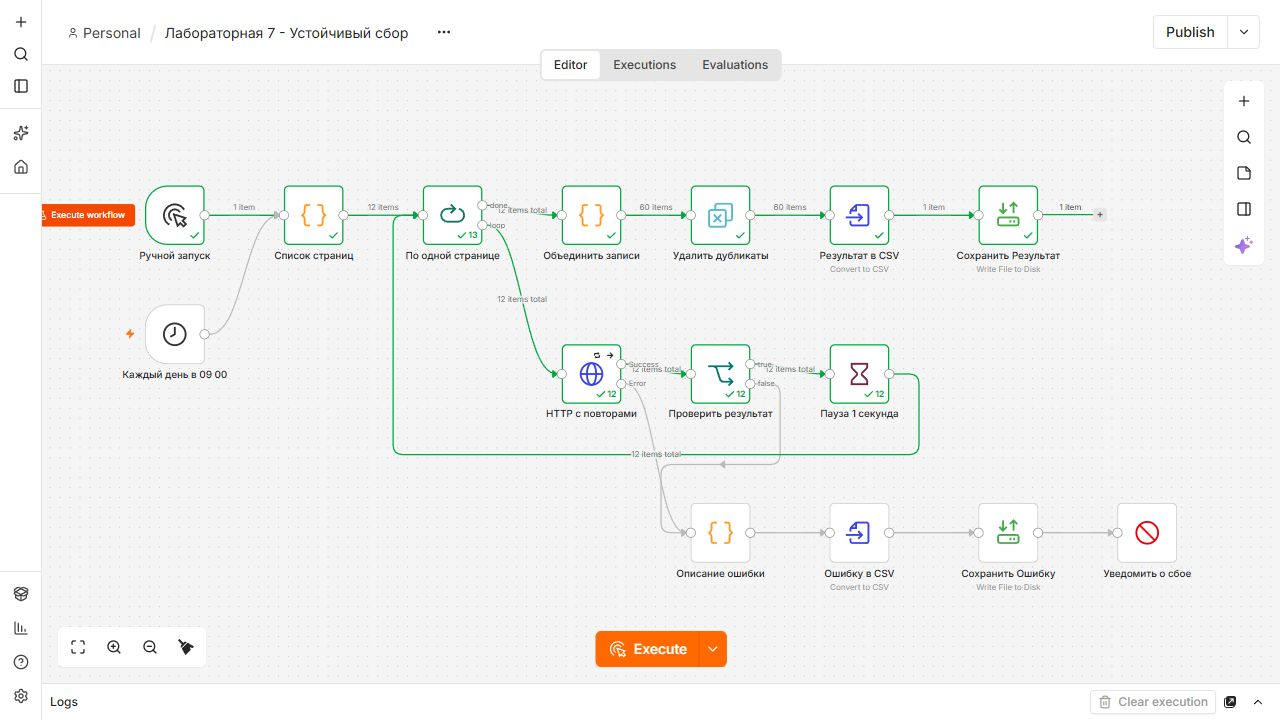

In [7]:
display(Image(filename=str(BASE / "nocode/screenshot_success.png")))

### 2.2. Сравнение с Python

Ограничения визуального сценария и расчёт стоимости:

In [8]:
display(Markdown((BASE / "nocode/nocode_notes.md").read_text(encoding="utf-8")))

# Сценарий n8n

В `workflow.json` 15 узлов. Ручной запуск или расписание формирует 12 адресов локального стенда. Loop Over Items обрабатывает по одной странице, HTTP Request получает данные, IF проверяет HTTP 200 и наличие как минимум пяти строк. Wait выдерживает одну секунду между страницами. После цикла записи объединяются, очищаются от дублей и сохраняются в CSV.

Контрольный запуск сохранил 60 уникальных записей за 14,888 с. Два намеренных разрыва соединения вызвали два повтора: всего 14 HTTP-запросов на 12 страниц. Измерения находятся в `execution_summary.json` и `http_observations.json`. Скриншот `screenshot_success.png` показывает отдельный успешный повторный запуск в редакторе.

У HTTP Request включены Retry On Fail, три попытки и задержка 1000 мс. Параметр Never Error позволяет передавать HTTP-ошибки в IF, поэтому 403 не повторяется. После исчерпания сетевых повторов используется выход Error. Обе ветки ошибок создают CSV и завершают выполнение узлом Stop And Error: это локальное уведомление, внешняя рассылка не настроена.

`workflow_error_test.json` отправляет один запрос к локальному ответу 403. Результат в `error_test_summary.json`: ожидаемая ошибка, один HTTP-запрос, файл `error_log.csv`. Два разрыва соединения основного сценария воспроизводятся только после перезапуска стенда.

| Возможность | Python | n8n |
|---|---|---|
| Ограничение скорости | Token bucket отдельно по доменам | Один последовательный цикл с Wait |
| Адаптивная задержка и jitter | Реализованы | Не реализованы |
| Повторы | Классификация, Retry-After, full jitter и бюджет | Фиксированная задержка для сетевых сбоев |
| Проверка результата | Маркеры блокировки, схема, история | IF: статус и число строк |
| Предохранитель | Closed, open, half-open по домену | Не реализован |
| Условные запросы и watermark | Постоянное состояние | Не реализованы |
| Лимит для нескольких процессов | Один владелец домена через файл | Не реализован |
| Ошибки | JSONL и сохранённые ответы | CSV и локальное уведомление |

Расписание настроено на каждый день в 09:00 по Перми (Asia/Yekaterinburg). Workflow не опубликован, автоматические запуски выключены. Для 30 ежедневных запусков получается 360 запросов за месяц без повторов. Используется локальная Community Edition: отдельной платы за выполнения нет; требуются ресурсы компьютера и Docker. Облачный тариф не используется.

Для воспроизведения выполнить `python -m src.fixtures`, затем `docker compose -f nocode/compose.yaml up -d`, открыть http://localhost:5688 и импортировать workflow. Стенд используется только для безопасной демонстрации сбоев; реальный контроль трёх сайтов выполнен Python-клиентом и описан в основном отчёте.

Сохранённые замеры и скриншот n8n получены 26.10.2026. В копии для сдачи изменены только порты локального запуска: стенд 8768, n8n 5688.

[Документация Community Edition](https://docs.n8n.io/hosting/community-edition-features/).


# Часть 3. Правовой чек-лист

In [9]:
display(Markdown((BASE / "legal_checklist.md").read_text(encoding="utf-8")))

# Правовой чек-лист

Проверено 26.10.2026. Источники взяты из лабораторных 3–5. Контрольные сбои создаются только на собственном локальном HTTP-стенде.

| Пункт | Ответ |
|---|---|
| Источники и назначение | books.toscrape.com — учебный каталог; scrapingcourse.com/button-click — учебная задача; api.worldbank.org — открытые агрегированные показатели |
| Цель | Учебная проверка устойчивости и воспроизводимости сбора |
| Условия использования | Books прямо обозначен как учебный sandbox. ScrapingCourse публикует задачу Load More для тренировки; выбранный путь разрешён robots.txt, отдельный договор на автоматический сбор не обнаружен на странице задания. World Bank допускает повторное использование данных по CC BY 4.0, если для показателя не указаны иные условия; источник указан |
| robots.txt | Books и World Bank: HTTP 404, явные правила не опубликованы; can_fetch=True. ScrapingCourse: HTTP 200, /ecommerce/* запрещён, /button-click разрешён. Crawl-delay и request_rate не заданы, Sitemap не объявлен в полученных файлах |
| Авторизация | Нет |
| Обход защиты | Нет: без капчи, маскировки, ротации IP, чужих токенов |
| Частота и пик | На домен один запрос одновременно; Books ≤2 запросов/с, ScrapingCourse ≤1, World Bank ≤1,5, burst=1. Дополнительные задержки зависят от ответа |
| Объём | Во внешнем контроле 7 HTTP-запросов, включая 3 robots.txt и повторный условный GET; 35 записей. A/B/C выполняются только локально |
| Состав и персональные данные | Названия и цены учебных товаров, агрегированное население стран. Профили, контакты и сведения об отдельных людях не собираются |
| Правовое основание при наличии ПД | Для собранного набора обработка индивидуальных ПД не является целью. При добавлении таких данных необходимо отдельно проверить основание по 152-ФЗ и применимость GDPR, соблюдать минимизацию. ФИО автора на отчёте — оформление учебной работы |
| Место и срок хранения | Локальная папка работы и локальный Docker, до завершения курса. Затем удалить папку, копии и соответствующий том n8n; чужие контейнеры не затрагивать |
| Контакт User-Agent | Предоставленный контакт test@mail.ru; заголовок VshivkovUniversityLab7/1.0 (educational; contact=test@mail.ru). Использован в сохранённом контрольном прогоне; переопределяется через LAB7_CONTACT |
| Претензия или блокировка | Остановить домен, сохранить диагностику, не повторять запросы в обход запрета; уточнить условия у владельца и удалить данные по обоснованному требованию |

404 robots.txt не отменяет условия использования. Исторический год показателя World Bank хранится отдельно от даты его получения. Данные предназначены для учебного анализа; изображения и полные описания книг не входят в итоговый набор.

Источники:

- [Books to Scrape](https://books.toscrape.com/)
- [ScrapingCourse Load More](https://www.scrapingcourse.com/button-click)
- [ScrapingCourse robots.txt](https://www.scrapingcourse.com/robots.txt)
- [World Bank Terms of Use](https://data.worldbank.org/summary-terms-of-use)
- [RFC 9309 — robots.txt](https://www.rfc-editor.org/rfc/rfc9309.html)
- [152-ФЗ](https://www.consultant.ru/document/cons_doc_LAW_61801/)
- [GDPR — официальный текст](https://eur-lex.europa.eu/eli/reg/2016/679/oj)


# Итоговый вывод

Предохранитель останавливает запросы к неисправному домену, остальные источники продолжают работу. Повторы восстанавливают потерянную страницу, а ETag, gzip и watermark уменьшают трафик. Режим C сохраняет все 60 записей. n8n подходит для последовательного сбора с паузами и простыми проверками; управление доменами и состоянием реализовано в Python.

### Источники

- [Пример занятия 7](https://colab.research.google.com/drive/1Wf627kgsKoIhWn7Wj1Hog3w5dVaK9am4)
- [HTTP и Retry-After](https://www.rfc-editor.org/rfc/rfc9110.html)
- [urllib.robotparser](https://docs.python.org/3/library/urllib.robotparser.html)
- [n8n Community Edition](https://docs.n8n.io/hosting/community-edition-features/)
